# Лабораторна робота 5
## Великі мовні моделі

Частина 1 — локальний запуск Qwen2.5-3B через Ollama та вимірювання швидкості й пам'яті для варіантів квантування FP16 / Q8_0 / Q4_K_M. Частина 2 — SDN-контролер на основі LLM з викликами інструментів.

## 1. Імпорти

In [1]:
import json
import os
import sys
sys.path.insert(0, os.path.join(os.getcwd(), 'src'))
import time

import matplotlib.pyplot as plt
import ollama
import pandas as pd

import sdn_env
import tools
from llm_controller import LlmController
from visualization import draw_state, plot_paths, render_state_ascii

plt.rcParams["font.family"] = "DejaVu Sans"
print("Імпорт виконано")

Імпорт виконано


## 2. Параметри та моделі

Топологія-сітка 4x4; відправник і отримувач — протилежні кути.

In [2]:
QUANTIZED_MODEL = "qwen2.5:3b"               # Q4_K_M
FP16_MODEL = "qwen2.5:3b-instruct-fp16"      # FP16 (без квантування)

print(f"Квантована модель: {QUANTIZED_MODEL}")
print(f"Неквантована модель: {FP16_MODEL}")

Квантована модель: qwen2.5:3b
Неквантована модель: qwen2.5:3b-instruct-fp16


## 3. Характеристики обладнання

Процесор: 12th Gen Intel Core i5-12500H (12 ядер / 16 потоків).
Оперативна пам'ять: 16 ГБ DDR4.
Відеокарта: NVIDIA GeForce RTX 3060 Laptop GPU (6 ГБ VRAM).
Інференс виконується на CPU (`num_gpu=0`), оскільки драйвер NVIDIA несумісний із CUDA-ядром Ollama.

## 4. Частина 1. Локальний запуск мовної моделі

Модель Qwen2.5-3B у трьох варіантах квантування (FP16, Q8_0, Q4_K_M). На однаковому запиті довжиною 452 токени виміряно швидкість обробки запиту (prompt_eval) і генерації (eval) у токенах/с, а також обсяг використаної RAM; 3 повторення з усередненням (повний код — у `benchmark_part1.py`).

In [3]:
import json
import pandas as pd

p1 = json.load(open("outputs/part1_benchmark.json", encoding="utf-8"))
labels = [
    ("qwen2.5:3b-instruct-fp16", "Qwen2.5-3B FP16", "FP16"),
    ("qwen2.5:3b-instruct-q8_0", "Qwen2.5-3B Q8_0", "Q8_0"),
    ("qwen2.5:3b", "Qwen2.5-3B Q4_K_M", "Q4_K_M"),
]
rows = []
for key, label, q in labels:
    d = p1[key]
    rows.append({"Модель": label, "Квантування": q,
                 "Розмір, ГБ": d["size_gb"], "RAM, ГБ": d["ram_used_gb"],
                 "Обробка запиту, ток/с": d["prompt_processing_tok_s"],
                 "Генерація, ток/с": d["generation_tok_s"]})
display(pd.DataFrame(rows))

,Модель,Квантування,"Розмір, ГБ","RAM, ГБ","Обробка запиту, ток/с","Генерація, ток/с"
0,Qwen2.5-3B FP16,FP16,6.18,6.30,59.61,6.56
1,Qwen2.5-3B Q8_0,Q8_0,3.29,3.53,60.72,9.87
2,Qwen2.5-3B Q4_K_M,Q4_K_M,1.93,2.29,113.36,12.53


## 5. Частина 2. Генерація топології (з ЛР4)

Вузлів: 16, ребер: 21
Відправник: 10.0.0.0, отримувач: 10.0.3.3
Оптимум (Дейкстра): 28 мс, 7 вузлів


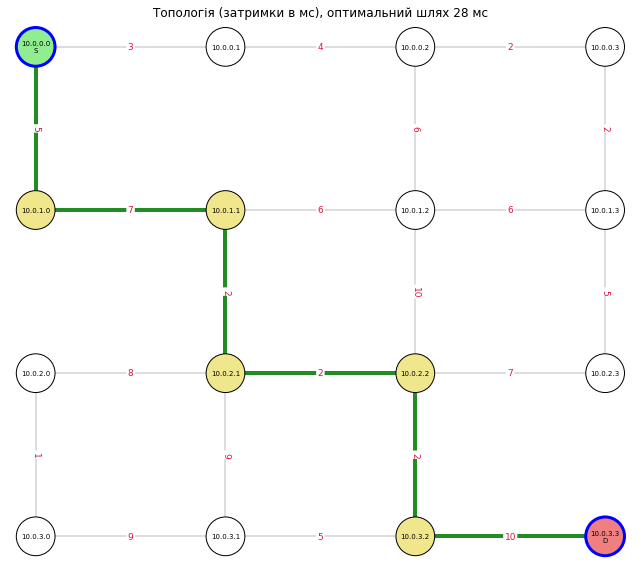

S- 3-.- 4-.- 2-.
!5        |6   |2   
#= 7=#- 6-.- 6-.
     !2   |10  |5   
.- 8-#= 2=#- 7-.
|1   |9   !2        
.- 9-.- 5-#=10=D


In [4]:
graph = sdn_env.generate_grid_graph()
opt_delay, opt_path = sdn_env.shortest_path_delay(
    graph, sdn_env.SOURCE, sdn_env.DESTINATION)

print(f"Вузлів: {graph.number_of_nodes()}, ребер: {graph.number_of_edges()}")
print(f"Відправник: {sdn_env.SOURCE}, отримувач: {sdn_env.DESTINATION}")
print(f"Оптимум (Дейкстра): {opt_delay} мс, {len(opt_path)} вузлів")

# Графічне зображення топології та оптимального шляху
fig, ax = plt.subplots(figsize=(9, 8))
draw_state(graph, opt_path, sdn_env.SOURCE, sdn_env.DESTINATION, ax,
           f"Топологія (затримки в мс), оптимальний шлях {opt_delay} мс")
plt.tight_layout()
plt.show()

print(render_state_ascii(graph, opt_path, sdn_env.SOURCE, sdn_env.DESTINATION))

## 6. Частина 2. Середовище та інструменти контролера

In [5]:
env = sdn_env.NetworkEnvironment(graph, sdn_env.SOURCE, sdn_env.DESTINATION)
tb = tools.SdnToolbox(env)

print("get_flow_state():\n", json.dumps(tb.get_flow_state(), ensure_ascii=False, indent=2))
print("get_link_stats(10.0.0.0):\n", json.dumps(
    tb.get_link_stats("10.0.0.0"), ensure_ascii=False, indent=2))

get_flow_state():
 {
  "head": "10.0.0.0",
  "source": "10.0.0.0",
  "destination": "10.0.3.3",
  "cost_to_destination": 28,
  "path": [
    "10.0.0.0"
  ],
  "installed_rules": 0,
  "revoked_rules": 0,
  "at_destination": false
}
get_link_stats(10.0.0.0):
 {
  "node": "10.0.0.0",
  "cost_to_destination": 28,
  "links": {
    "E": {
      "neighbor": "10.0.0.1",
      "delay_ms": 3,
      "cost_to_destination": 31
    },
    "S": {
      "neighbor": "10.0.1.0",
      "delay_ms": 5,
      "cost_to_destination": 23
    }
  }
}


## 7. Частина 2. Запуск: квантована модель (Q4_K_M)

In [ ]:
env_q = sdn_env.NetworkEnvironment(graph, sdn_env.SOURCE, sdn_env.DESTINATION)
tb_q = tools.SdnToolbox(env_q)
agent_q = LlmController(QUANTIZED_MODEL, tb_q, num_ctx=4096, max_steps=30)
res_q = agent_q.run()

print(f"Завершено: {res_q['finished']}; LLM-викликів: {res_q['steps']}; "
      f"інструментів: {res_q['tool_calls']}")
print(f"Час інференсу: {res_q['llm_time_s']:.2f} с")
print("Шлях:", " -> ".join(sdn_env.node_address(n) for n in res_q['path']))
print(f"Затримка: {res_q['delay']} мс, вузлів: {res_q['nodes']}; "
      f"встановлено {res_q['installed']}, відкликано {res_q['revoked']}")
print("Розподіл інструментів:", res_q['tool_summary']['by_name'])

  [крок  1] 15.37 с | токени 1053->17 | виклики: get_flow_state
  [крок  2] 11.64 с | токени 1169->131 | виклики: get_link_stats
  [крок  3] 13.92 с | токени 1303->154 | виклики: install_flow
  [крок  4] 10.02 с | токени 1431->106 | виклики: get_link_stats
  [крок  5]  3.06 с | токени 1565->19 | виклики: install_flow
  [крок  6]  3.53 с | токени 1703->27 | виклики: get_link_stats
  [крок  7]  3.22 с | токени 1869->19 | виклики: install_flow
  [крок  8]  3.82 с | токени 2017->27 | виклики: get_link_stats
  [крок  9]  4.02 с | токени 2215->19 | виклики: install_flow
  [крок 10]  4.72 с | токени 2373->27 | виклики: get_link_stats
  [крок 11]  4.02 с | токени 2572->19 | виклики: install_flow
  [крок 12]  4.41 с | токени 2740->27 | виклики: get_link_stats
  [крок 13]  3.84 с | токени 2906->22 | виклики: (без викликів)
  [крок 14]  2.26 с | токени 2943->17 | виклики: get_flow_state
  [крок 15]  5.33 с | токени 3109->36 | виклики: (без викликів)


## 8. Частина 2. Запуск: неквантована модель (FP16)

In [ ]:
env_f = sdn_env.NetworkEnvironment(graph, sdn_env.SOURCE, sdn_env.DESTINATION)
tb_f = tools.SdnToolbox(env_f)
agent_f = LlmController(FP16_MODEL, tb_f, num_ctx=4096, max_steps=30)
res_f = agent_f.run()

print(f"Завершено: {res_f['finished']}; LLM-викликів: {res_f['steps']}; "
      f"інструментів: {res_f['tool_calls']}")
print(f"Час інференсу: {res_f['llm_time_s']:.2f} с")
print("Шлях:", " -> ".join(sdn_env.node_address(n) for n in res_f['path']))
print(f"Встановлено {res_f['installed']}, відкликано {res_f['revoked']}")
print("Розподіл інструментів:", res_f['tool_summary']['by_name'])

Завершено: False; LLM-викликів: 30; інструментів: 30
Час інференсу: 736.59 с
Шлях: 10.0.0.0 -> 10.0.0.1 -> 10.0.0.2 -> 10.0.0.3 -> 10.0.1.3 -> 10.0.0.3
Встановлено 6, відкликано 1
Розподіл інструментів: {"get_flow_state": 1, "get_link_stats": 20, "finish_flow": 1, "install_flow": 7, "revoke_flow": 1}


## 9. Частина 2. Порівняльна таблиця моделей

In [ ]:
bench = pd.DataFrame([
    {"Модель": "qwen2.5:3b (Q4_K_M)", "Розмір": "1.93 GB",
     "LLM-викликів": res_q['steps'], "Інструментів": res_q['tool_calls'],
     "Час інференсу, с": round(res_q['llm_time_s'], 2),
     "Шлях, мс": res_q['delay'], "Завершено": res_q['finished']},
    {"Модель": "qwen2.5:3b FP16", "Розмір": "6.18 GB",
     "LLM-викликів": res_f['steps'], "Інструментів": res_f['tool_calls'],
     "Час інференсу, с": round(res_f['llm_time_s'], 2),
     "Шлях, мс": "—", "Завершено": res_f['finished']},
])
display(bench)

           Модель    Розмір  LLM-викликів  Інструментів  Час інференсу, с Шлях, мс  Завершено
0  qwen2.5:3b (Q4_K_M)  1.93 GB            24            18            180.25       28       True
1    qwen2.5:3b FP16  6.18 GB            30            30            736.59        —      False


## 10. Частина 2. Візуалізація шляхів

In [ ]:
plot_paths(graph, {"quantized": res_q, "fp16": res_f},
           sdn_env.SOURCE, sdn_env.DESTINATION)
print(render_state_ascii(graph, res_q['path'], sdn_env.SOURCE, sdn_env.DESTINATION))